# Лабораторная работа №1. Первичное исследование и оценка качества данных

Датасет: `online_store_customers.csv` (клиенты интернет-магазина).

# 1. Постановка задачи

## 1.1. Что это за данные
Датасет описывает клиентов и покупки интернет-магазина товаров для дома, спорта, красоты, одежды и электроники. Каждая строка соответствует одному клиенту: указаны его пол, возраст, город, ежемесячный доход, любимая категория товаров, способ оплаты, дата заказа, число заказов, средний чек и общая сумма покупок. В файле 1003 строки и 11 признаков: числовые, категориальные и временной (`order_date`, период 2025 года). Судя по названиям и значениям, данные синтетические, и в них намеренно заложены типичные проблемы качества: пропуски, дубликаты, невозможные значения, «грязные» категории и выбросы.

## 1.2. Условный заказчик анализа
Заказчик: **отдел маркетинга и CRM интернет-магазина**. Его интересует, кто покупает, сколько тратит и чем различаются группы клиентов. Заинтересованы также менеджеры по категориям (ассортимент) и финансовый отдел (способы оплаты, выручка).

## 1.3. Возможные задачи интеллектуального анализа данных
1. **Сегментация клиентов (кластеризация).** По возрасту, доходу, числу заказов, среднему чеку и категории выделить группы клиентов (например, «редкие экономные», «частые с высоким чеком») и подобрать для каждой свои акции.
2. **Прогнозирование суммы покупок (регрессия).** Предсказывать `total_spent` по демографии и поведению клиента, чтобы оценивать ценность нового клиента.
3. **Поиск аномалий.** Находить подозрительные записи: нереалистичные суммы, чеки, не сходящиеся с числом заказов, возможное мошенничество или ошибки учётной системы.
4. **Описательная аналитика.** Профилировать группы: как категория товара, город и способ оплаты связаны с чеком и частотой покупок.

# 2. Паспорт датасета

Загружаем данные, определяем размер, смотрим типы признаков и формулируем гипотезы об их смысле. Описания столбцов в файле нет, поэтому смысл признаков — наши гипотезы по названиям.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

DATA_PATH = "../data/online_store_customers.csv"
df_raw = pd.read_csv(DATA_PATH)   # исходные данные сохраняем без изменений
df = df_raw.copy()                # рабочая копия

In [2]:
n_rows, n_cols = df.shape
print(f"Количество строк:    {n_rows}")
print(f"Количество столбцов: {n_cols}")

Количество строк:    1003
Количество столбцов: 11


In [3]:
meaning = {
    "customer_id":      "идентификатор клиента (строка вида C0001)",
    "order_date":       "дата (и время) заказа",
    "age":              "возраст клиента, лет",
    "gender":           "пол клиента",
    "city":             "город клиента",
    "product_category": "категория купленного товара",
    "payment_method":   "способ оплаты",
    "orders_count":     "число заказов клиента",
    "average_check":    "средний чек, руб.",
    "customer_income":  "доход клиента (вероятно, в месяц), руб.",
    "total_spent":      "общая сумма покупок клиента, руб.",
}
passport = pd.DataFrame({
    "Тип (pandas)": df.dtypes.astype(str),
    "Непустых": df.notna().sum(),
    "Уникальных": df.nunique(),
    "Предположительный смысл": pd.Series(meaning),
})
display(passport)

,Тип (pandas),Непустых,Уникальных,Предположительный смысл
customer_id,str,1003,1000,идентификатор клиента (строка вида C0001)
order_date,str,1003,1000,дата (и время) заказа
age,float64,954,51,"возраст клиента, лет"
gender,str,1003,2,пол клиента
city,str,973,8,город клиента
product_category,str,1003,5,категория купленного товара
payment_method,str,1003,5,способ оплаты
orders_count,int64,1003,10,число заказов клиента
average_check,float64,962,953,"средний чек, руб."
customer_income,float64,942,929,"доход клиента (вероятно, в месяц), руб."


In [4]:
display(df.head())

,customer_id,order_date,age,gender,city,product_category,payment_method,orders_count,average_check,customer_income,total_spent
0,C0001,2025-01-01 00:00:00.000000000,40.0,Мужской,москва,Дом,СБП,4,5308.234925,81149.252924,24784.49
1,C0002,2025-01-01 08:44:41.081081081,33.0,Женский,москва,Спорт,Наличные,8,6120.498456,112643.261873,48652.91
2,C0003,2025-01-01 17:29:22.162162162,42.0,Мужской,москва,Дом,Наличные,1,3533.350061,57193.692017,7131.58
3,C0004,2025-01-02 02:14:03.243243243,52.0,Женский,москва,Электроника,Наличные,4,3986.018703,94786.937210,17006.32
4,C0005,2025-01-02 10:58:44.324324324,32.0,Мужской,МОСКВА,Спорт,СБП,6,NaN,25000.000000,28130.69


### Приведение типов

- `order_date` читается как строка, поэтому приводим к `datetime`.
- `age` хранится как `float` из-за пропусков. Целочисленный тип `Int64` (с поддержкой пропусков) включим после очистки невозможных значений в п. 3.3.
- `gender`, `city`, `product_category`, `payment_method` — категориальные признаки. В `category` их переведём после нормализации «грязных» значений (п. 3.3): иначе разные написания одного значения станут разными категориями.
- `customer_id` — идентификатор, оставляем строкой. Числа в нём не имеют математического смысла.

In [5]:
df["order_date"] = pd.to_datetime(df["order_date"])
print("Период заказов:", df["order_date"].min().date(), "—", df["order_date"].max().date())
display(df.dtypes.to_frame("Тип после приведения"))

Период заказов: 2025-01-01 — 2025-12-31


,Тип после приведения
customer_id,str
order_date,datetime64[ns]
age,float64
gender,str
city,str
product_category,str
payment_method,str
orders_count,int64
average_check,float64
customer_income,float64


# 3. Аудит качества данных

Проверяем пропуски, дубликаты, подозрительные значения и выбросы. Все решения по очистке фиксируем здесь же, а итоговую таблицу проблем даём в `report/quality_report.md`.

## 3.1. Пропуски

In [6]:
missing = pd.DataFrame({
    "Количество пропусков": df.isna().sum(),
    "Доля, %": (df.isna().mean() * 100).round(2),
})
missing_nz = missing[missing["Количество пропусков"] > 0].sort_values("Количество пропусков", ascending=False)
display(missing_nz)

per_row = df.isna().sum(axis=1)
print("\nСтрок с 0 / 1 / 2 пропусками:", per_row.value_counts().sort_index().to_dict())
print("Строк хотя бы с одним пропуском:", int((per_row > 0).sum()), f"({(per_row > 0).mean()*100:.1f}%)")

,Количество пропусков,"Доля, %"
customer_income,61,6.08
age,49,4.89
average_check,41,4.09
city,30,2.99



Строк с 0 / 1 / 2 пропусками: {0: 831, 1: 163, 2: 9}
Строк хотя бы с одним пропуском: 172 (17.1%)


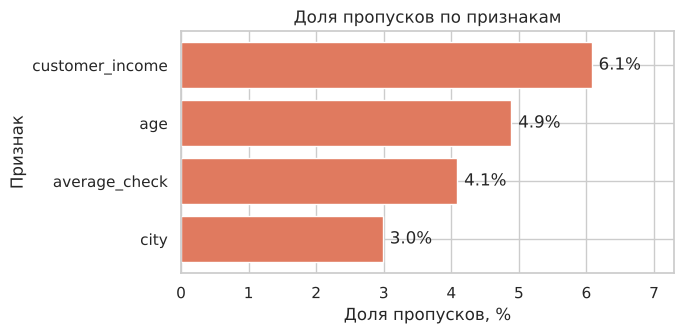

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(missing_nz.index[::-1], missing_nz["Доля, %"][::-1], color="#e07a5f")
for i, v in enumerate(missing_nz["Доля, %"][::-1]):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center")
ax.set_title("Доля пропусков по признакам")
ax.set_xlabel("Доля пропусков, %")
ax.set_ylabel("Признак")
ax.set_xlim(0, missing_nz["Доля, %"].max() * 1.2)
plt.tight_layout()
plt.show()

**Вывод по пропускам.** Пропуски есть в четырёх признаках: `customer_income` (61, 6.08%), `age` (49, 4.89%), `average_check` (41, 4.09%) и `city` (30, 2.99%). Это немного, и ни один признак не пропущен массово. Хотя бы один пропуск есть в 17% строк, поэтому удалять строки целиком нельзя: потеряем почти пятую часть данных.

- **Наиболее проблемный признак — `customer_income`.** Доход, вероятно, важный признак для сегментации, и в нём больше всего дыр. Заполнять его придётся с оценкой смещения (медиана внутри групп или модель).
- **`average_check` — пропуски не критичны.** Они восстанавливаются: средний чек ≈ `total_spent / orders_count`, а оба поля в этих строках заполнены (проверим в п. 3.3).
- **`age`.** Пропуски умеренные. Для кластеризации возраст нужен, поэтому либо импутация медианой по группам, либо отдельная категория «возраст неизвестен».
- **`city`.** Пропуски редкие, их безопасно заполнить значением `Неизвестно`: на числовые признаки это не влияет.
- Помимо явных пропусков, в данных есть **«скрытые» пропуски и заглушки** (например, значения на нижней границе). Они разобраны в п. 3.3.

## 3.2. Дубликаты

In [8]:
n_full_dup = df.duplicated().sum()
n_id_dup = df["customer_id"].duplicated().sum()
print(f"Полностью дублирующихся строк: {n_full_dup}")
print(f"Повторяющихся customer_id:      {n_id_dup}")

dup_ids = df.loc[df["customer_id"].duplicated(), "customer_id"]
display(df[df["customer_id"].isin(dup_ids)].sort_values(["customer_id"]))

# совпадают ли дубли по ID с дублями по всей строке?
conflict = df.drop_duplicates()["customer_id"].duplicated().sum()
print(f"\nПовторов customer_id с РАЗНЫМИ данными (конфликты): {conflict}")

Полностью дублирующихся строк: 3
Повторяющихся customer_id:      3


,customer_id,order_date,age,gender,city,product_category,payment_method,orders_count,average_check,customer_income,total_spent
50,C0051,2025-01-19 05:14:14.054054054,39.0,Мужской,Самара,Одежда,Наличные,4,2037.532280,NaN,9320.51
1000,C0051,2025-01-19 05:14:14.054054054,39.0,Мужской,Самара,Одежда,Наличные,4,2037.532280,NaN,9320.51
51,C0052,2025-01-19 13:58:55.135135135,31.0,Мужской,Новосибирск,Спорт,Карта,2,5440.054462,114188.357063,11523.20
1001,C0052,2025-01-19 13:58:55.135135135,31.0,Мужской,Новосибирск,Спорт,Карта,2,5440.054462,114188.357063,11523.20
52,C0053,2025-01-19 22:43:36.216216216,28.0,Мужской,Новосибирск,Дом,Карта,2,NaN,75743.723234,6628.40
1002,C0053,2025-01-19 22:43:36.216216216,28.0,Мужской,Новосибирск,Дом,Карта,2,NaN,75743.723234,6628.40



Повторов customer_id с РАЗНЫМИ данными (конфликты): 0


In [9]:
df = df.drop_duplicates().reset_index(drop=True)
print("Строк после удаления дубликатов:", len(df))
print("customer_id теперь уникален:", df["customer_id"].is_unique)

Строк после удаления дубликатов: 1000
customer_id теперь уникален: True


**Вывод.** Найдено 3 полностью одинаковых строки: клиенты `C0051`–`C0053` записаны дважды, второй раз в самом конце файла (строки 1001–1003). Конфликтов (один ID с разными данными) нет, то есть это именно технический дубль, например повторная загрузка фрагмента. Дубли удалены, `customer_id` стал уникальным. Если их оставить, три клиента посчитаются дважды, что исказит распределения и средние.

## 3.3. Типичные проблемы значений

### Числовые признаки

In [10]:
num_cols = ["age", "orders_count", "average_check", "customer_income", "total_spent"]
stats_tbl = df[num_cols].agg(["min", "max", "mean", "std"]).T
stats_tbl["медиана"] = df[num_cols].median()
display(stats_tbl.round(2))

,min,max,mean,std,медиана
age,-5.0,150.0,35.45,11.07,35.00
orders_count,1.0,10.0,3.97,1.60,4.00
average_check,500.0,85000.0,4314.15,3753.37,4139.85
customer_income,25000.0,250000.0,77339.14,36868.17,69622.77
total_spent,300.0,750000.0,17703.73,29425.95,14703.16


In [11]:
# Проверка правдоподобия по простым предметным правилам
rules = {
    "age < 14 или age > 100":          (df["age"] < 14) | (df["age"] > 100),
    "orders_count < 1":                 df["orders_count"] < 1,
    "average_check <= 0":               df["average_check"] <= 0,
    "total_spent <= 0":                 df["total_spent"] <= 0,
    "customer_income <= 0":             df["customer_income"] <= 0,
}
print(pd.Series({k: int(v.sum()) for k, v in rules.items()}, name="Нарушений").to_string())
print("\nНевозможные значения возраста:")
display(df.loc[rules["age < 14 или age > 100"], ["customer_id", "age"]])

age < 14 или age > 100    3
orders_count < 1          0
average_check <= 0        0
total_spent <= 0          0
customer_income <= 0      0

Невозможные значения возраста:


,customer_id,age
10,C0011,-5.0
20,C0021,0.0
30,C0031,150.0


In [12]:
# Нагромождение значений на границах (признак «заглушек» или обрезки)
floor_tbl = []
for c in ["total_spent", "average_check", "customer_income"]:
    mn, mx = df[c].min(), df[c].max()
    floor_tbl.append({
        "Признак": c,
        "Минимум": mn, "Строк с минимумом": int((df[c] == mn).sum()),
        "Следующее значение": round(df.loc[df[c] > mn, c].min(), 2),
        "Максимум": mx, "Строк с максимумом": int((df[c] == mx).sum()),
    })
display(pd.DataFrame(floor_tbl))

,Признак,Минимум,Строк с минимумом,Следующее значение,Максимум,Строк с максимумом
0,total_spent,300.0,13,387.21,750000.0,1
1,average_check,500.0,8,611.09,85000.0,1
2,customer_income,25000.0,11,25118.18,250000.0,2


In [13]:
# Логическая согласованность: total_spent ≈ orders_count * average_check ?
expected = df["orders_count"] * df["average_check"]
ratio = df["total_spent"] / expected
print(ratio.describe().round(3).to_string())

mismatch = (ratio < 0.5) | (ratio > 2)
print(f"\nСтрок, где total_spent отличается от orders_count*average_check более чем в 2 раза: {int(mismatch.sum())}")

cols = ["customer_id", "orders_count", "average_check", "total_spent"]
tmp = df.loc[mismatch, cols].assign(ожидалось=expected[mismatch].round(0), отношение=ratio[mismatch].round(2))
print("\nСамые «кричащие» несоответствия:")
display(tmp.sort_values("отношение", key=lambda s: np.log(s).abs(), ascending=False).head(8))

# можно ли восстановить пропущенный средний чек?
can_restore = df["average_check"].isna() & df["total_spent"].notna() & (df["orders_count"] > 0)
print(f"\nПропусков average_check, которые можно восстановить как total_spent/orders_count: {int(can_restore.sum())} из {int(df['average_check'].isna().sum())}")

count    960.000
mean       1.114
std        2.447
min        0.024
25%        0.883
50%        1.003
75%        1.112
max       57.059

Строк, где total_spent отличается от orders_count*average_check более чем в 2 раза: 50

Самые «кричащие» несоответствия:


,customer_id,orders_count,average_check,total_spent,ожидалось,отношение
400,C0401,3,2920.972476,500000.00,8763.0,57.06
500,C0501,4,3652.226076,750000.00,14609.0,51.34
300,C0301,4,85000.000000,8040.08,340000.0,0.02
200,C0201,4,60000.000000,7166.75,240000.0,0.03
156,C0157,2,2920.856752,300.00,5842.0,0.05
987,C0988,4,1310.317591,300.00,5241.0,0.06
543,C0544,4,1006.009423,300.00,4024.0,0.07
100,C0101,4,45000.000000,12455.78,180000.0,0.07



Пропусков average_check, которые можно восстановить как total_spent/orders_count: 40 из 40


**Выводы по числовым признакам.**

- **Возраст.** Есть три невозможных значения: `-5`, `0` и `150` (клиенты `C0011`, `C0021`, `C0031`). Остальные значения лежат в диапазоне 18–75 лет. Невозможные значения заменим на пропуск.
- **Нагромождение на границах.** В `total_spent` ровно 13 строк со значением `300.00`, в `average_check` — 8 со значением `500.00`, а в `customer_income` — 11 со значением `25000`. Для непрерывных величин с шумом так не бывает: вероятно, это обрезка снизу (минимальная сумма или «заглушка» вместо пропуска). Эти значения нельзя считать настоящими наблюдениями без проверки.
- **Аномальный средний чек.** Три значения `45000`, `60000` и `85000` (клиенты `C0101`, `C0201`, `C0301`) в 6–11 раз превышают 99-й процентиль (~7650). При этом их `total_spent` — всего 7–12 тысяч, так что чек физически не может быть таким.
- **Экстремальные суммы.** `total_spent = 500000` и `750000` (клиенты `C0401`, `C0501`) примерно в 50 раз больше, чем `orders_count × average_check`. Следующее по величине значение — около 54 тысяч.
- **Согласованность признаков.** В целом `total_spent ≈ orders_count × average_check` (медианное отношение ≈ 1.0), поэтому нарушения отчётливо видны: их около 50 строк. Это дополнительный признак ошибок и хороший кандидат для проверки в задаче поиска аномалий.
- Пропущенный `average_check` восстанавливается во всех случаях (40 из 40 после удаления дубликатов).

### Категориальные признаки

In [14]:
cat_cols = ["gender", "city", "product_category", "payment_method"]
for c in cat_cols:
    vals = df[c].dropna().unique().tolist()
    print(f"{c}: {df[c].nunique()} уникальных (с пропуском {df[c].nunique(dropna=False)})")
    print("   ", [repr(v) for v in sorted(vals)])

gender: 2 уникальных (с пропуском 2)
    ["'Женский'", "'Мужской'"]
city: 8 уникальных (с пропуском 9)
    ["' москва '", "'Екатеринбург'", "'Казань'", "'МОСКВА'", "'Москва'", "'Новосибирск'", "'Самара'", "'Санкт-Петербург'"]
product_category: 5 уникальных (с пропуском 5)
    ["'Дом'", "'Красота'", "'Одежда'", "'Спорт'", "'Электроника'"]
payment_method: 5 уникальных (с пропуском 5)
    ["' карта '", "'Карта'", "'Наличные'", "'Онлайн'", "'СБП'"]


Видим «грязные» категории: в `city` встречаются `' москва '` (с пробелами и строчными), `'МОСКВА'` и `'Москва'`, а в `payment_method` — `' карта '` и `'Карта'`. Это одни и те же значения, записанные по-разному. Для `pandas` это разные категории, и они раздробят группы. Нормализуем: убираем пробелы по краям, сравниваем без учёта регистра и берём самое частое написание как каноническое.

In [15]:
def normalize_categories(s: pd.Series) -> pd.Series:
    """Убирает лишние пробелы, сводит регистр: каноническое написание — самое частое."""
    stripped = s.str.strip()
    key = stripped.str.casefold()
    canon = stripped.groupby(key).agg(lambda x: x.value_counts().idxmax())
    return key.map(canon)

df_clean = df.copy()
before = {c: df_clean[c].nunique() for c in cat_cols}
for c in cat_cols:
    df_clean[c] = normalize_categories(df_clean[c])
after = {c: df_clean[c].nunique() for c in cat_cols}
display(pd.DataFrame({"Уникальных до": before, "Уникальных после": after}))
print(df_clean["city"].value_counts(dropna=False).to_string())
print()
print(df_clean["payment_method"].value_counts(dropna=False).to_string())

,Уникальных до,Уникальных после
gender,2,2
city,8,6
product_category,5,5
payment_method,5,4


city
Екатеринбург       173
Москва             169
Самара             167
Новосибирск        160
Казань             159
Санкт-Петербург    142
NaN                 30

payment_method
Онлайн      265
Наличные    257
Карта       243
СБП         235


In [16]:
# Невозможный возраст -> пропуск; затем компактные типы
df_clean["age"] = df_clean["age"].where(df_clean["age"].between(14, 100)).astype("Int64")
for c in cat_cols:
    df_clean[c] = df_clean[c].astype("category")
display(df_clean.dtypes.to_frame("Тип в df_clean"))
print("Пропусков в age после очистки:", int(df_clean["age"].isna().sum()), "(было 49, +3 невозможных значения)")

,Тип в df_clean
customer_id,str
order_date,datetime64[ns]
age,Int64
gender,category
city,category
product_category,category
payment_method,category
orders_count,int64
average_check,float64
customer_income,float64


Пропусков в age после очистки: 52 (было 49, +3 невозможных значения)


**Вывод по категориям.** После нормализации в `city` осталось 6 городов вместо 8 написаний: 8 строк с нестандартной записью Москвы (`' москва '`, `'МОСКВА'`) присоединились к основной категории (всего 169 клиентов). В `payment_method` стало 4 способа вместо 5: `' карта '` объединена с `Карта`. Пол и категория товара были чистыми. Далее работаем с `df_clean`; исходные данные `df_raw` не менялись.

## 3.4. Выбросы

Метод — межквартильный размах (IQR): выбросом считаем значение вне `[Q1 − 1.5·IQR; Q3 + 1.5·IQR]`. Для контроля сравним с правилом z-score (`|z| > 3`). Основной признак для визуализации — `total_spent`, остальные числовые признаки сведены в таблицу.

In [17]:
def iqr_bounds(s):
    s = s.dropna().astype(float)
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1, q3, iqr, q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in ["age", "orders_count", "average_check", "customer_income", "total_spent"]:
    s = df_clean[c].dropna().astype(float)
    q1, q3, iqr, lo, hi = iqr_bounds(s)
    z = (s - s.mean()) / s.std()
    rows.append({
        "Признак": c, "Q1": q1, "Q3": q3, "IQR": iqr,
        "Нижняя граница": lo, "Верхняя граница": hi,
        "Выбросов (IQR)": int(((s < lo) | (s > hi)).sum()),
        "Выбросов (|z|>3)": int((z.abs() > 3).sum()),
        "% (IQR)": round(((s < lo) | (s > hi)).mean() * 100, 2),
    })
display(pd.DataFrame(rows).round(1))

,Признак,Q1,Q3,IQR,Нижняя граница,Верхняя граница,Выбросов (IQR),Выбросов (|z|>3),% (IQR)
0,age,28.0,42.0,14.0,7.0,63.0,3,2,0.3
1,orders_count,3.0,5.0,2.0,0.0,8.0,4,4,0.4
2,average_check,3115.3,5191.5,2076.2,1.0,8305.8,5,3,0.5
3,customer_income,50488.4,96032.1,45543.7,-17827.1,164347.6,31,14,3.3
4,total_spent,9433.0,21896.8,12463.8,-9262.7,40592.5,22,2,2.2


In [18]:
s = df_clean["total_spent"]
q1, q3, iqr, lo, hi = iqr_bounds(s)
out_mask = (s < lo) | (s > hi)
print(f"total_spent: Q1={q1:.0f}, Q3={q3:.0f}, IQR={iqr:.0f}, границы [{lo:.0f}; {hi:.0f}]")
print(f"Выбросов: {int(out_mask.sum())} из {len(s)} ({out_mask.mean()*100:.1f}%)\n")
print("Самые большие значения:")
display(df_clean.loc[out_mask, ["customer_id", "orders_count", "average_check", "total_spent"]]
        .sort_values("total_spent", ascending=False).head(8))

total_spent: Q1=9433, Q3=21897, IQR=12464, границы [-9263; 40593]
Выбросов: 22 из 1000 (2.2%)

Самые большие значения:


,customer_id,orders_count,average_check,total_spent
500,C0501,4,3652.226076,750000.00
400,C0401,3,2920.972476,500000.00
374,C0375,9,6468.796053,54165.39
237,C0238,7,7506.279252,53015.17
692,C0693,10,5562.333190,52830.81
384,C0385,6,8491.704851,52574.25
230,C0231,7,7310.668024,51502.13
915,C0916,7,7132.066796,49389.11


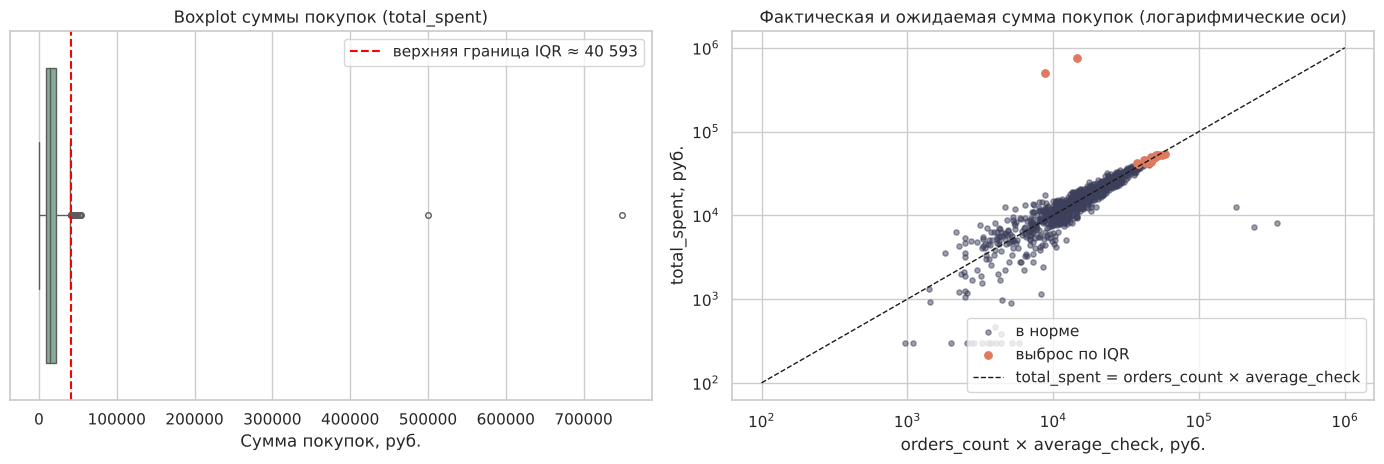

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.boxplot(x=s, ax=axes[0], color="#81b29a", fliersize=4)
axes[0].axvline(hi, color="red", linestyle="--", label=f"верхняя граница IQR ≈ {hi:,.0f}".replace(",", " "))
axes[0].set_title("Boxplot суммы покупок (total_spent)")
axes[0].set_xlabel("Сумма покупок, руб.")
axes[0].legend()

exp = df_clean["orders_count"] * df_clean["average_check"]
ok = ~out_mask
axes[1].scatter(exp[ok], s[ok], s=14, alpha=0.5, color="#3d405b", label="в норме")
axes[1].scatter(exp[out_mask], s[out_mask], s=28, color="#e07a5f", label="выброс по IQR")
lim = [100, 1e6]
axes[1].plot(lim, lim, "k--", linewidth=1, label="total_spent = orders_count × average_check")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Фактическая и ожидаемая сумма покупок (логарифмические оси)")
axes[1].set_xlabel("orders_count × average_check, руб.")
axes[1].set_ylabel("total_spent, руб.")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

**Вывод по выбросам.** По правилу IQR в `total_spent` выбросами названо 22 наблюдения (2.2%), по z-score — всего 2: правило 3σ ослеплено двумя экстремальными значениями, раздувшими стандартное отклонение, поэтому IQR здесь надёжнее. Выбросы бывают двух видов:

- **Ошибки (2 строки).** `500000` и `750000` лежат далеко от диагонали на правом графике: они в ~50 раз выше, чем `orders_count × average_check`. Это почти наверняка ошибки данных, их нельзя использовать в обучении без проверки.
- **Реальный «тяжёлый хвост» (20 строк).** Значения 41–54 тысячи лежат вдоль диагонали, то есть согласуются с числом заказов и чеком. Это настоящие крупные клиенты (в задаче сегментации они как раз интересны), удалять их не нужно.

Остальные признаки: у `average_check` 5 выбросов — три ошибочных чека 45–85 тысяч (см. п. 3.3) и два чека около 8.5 тысяч, лишь слегка выше границы; в `customer_income` 31 значение выше ≈ 164 тысяч — вероятно, настоящие высокие доходы (хвост идёт плавно до 250 тысяч); в `age` три значения старше 63 лет — правдоподобные клиенты старшего возраста, их оставляем.

# 4. Разведочный анализ

Для визуализаций берём очищенные данные `df_clean` и дополнительно исключаем заведомо ошибочные значения, найденные в аудите: 2 строки с `total_spent > 100 000` и 3 нереалистичных значения `average_check ≥ 20 000` (последние заменяем на пропуск). В исходных данных эти записи остаются, решение отражено в плане улучшения качества.

In [20]:
df_eda = df_clean[df_clean["total_spent"] <= 100_000].copy()
df_eda.loc[df_eda["average_check"] >= 20_000, "average_check"] = np.nan
df_eda["age"] = df_eda["age"].astype("float")
df_eda["month"] = df_eda["order_date"].dt.month
print("Строк для EDA:", len(df_eda))

Строк для EDA: 998


### 4.1. Распределение числового признака — сумма покупок

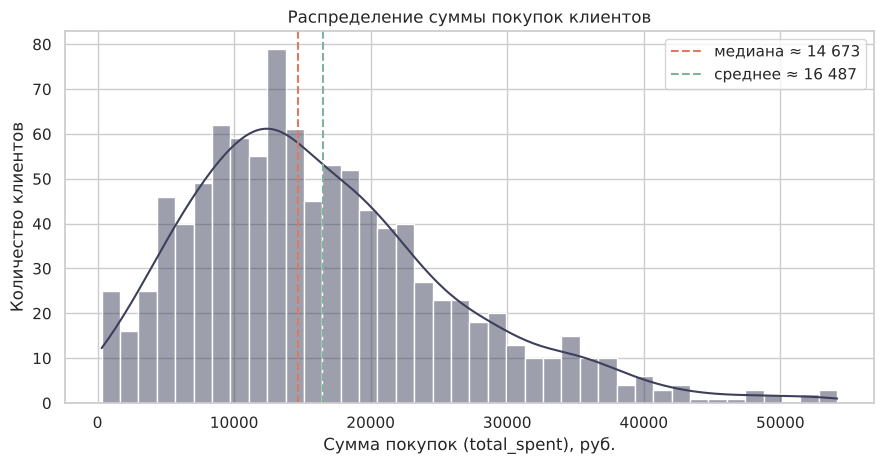

Асимметрия: 0.91


In [21]:
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.histplot(df_eda["total_spent"], bins=40, kde=True, color="#3d405b", ax=ax)
med, mean = df_eda["total_spent"].median(), df_eda["total_spent"].mean()
ax.axvline(med, color="#e07a5f", linestyle="--", label=f"медиана ≈ {med:,.0f}".replace(",", " "))
ax.axvline(mean, color="#81b29a", linestyle="--", label=f"среднее ≈ {mean:,.0f}".replace(",", " "))
ax.set_title("Распределение суммы покупок клиентов")
ax.set_xlabel("Сумма покупок (total_spent), руб.")
ax.set_ylabel("Количество клиентов")
ax.legend()
plt.tight_layout()
plt.show()
print("Асимметрия:", round(df_eda["total_spent"].skew(), 2))

**Что видно.** Распределение одномодальное и с правым хвостом: пик около 12–15 тысяч, половина клиентов тратит от 9 до 22 тысяч, а единицы — 40–54 тысячи. Среднее выше медианы, асимметрия положительная (≈ 0.9). В первом интервале у левого края заметен небольшой всплеск — это значения `300`.

**Гипотезы.** Распределение похоже на логнормальное, и для регрессии `total_spent` имеет смысл логарифмировать. Среднее хуже подходит как «типичное» значение, чем медиана.

**Вопросы.** Откуда берётся всплеск на 300 рублях: минимальный платёж или обрезка при выгрузке? Чем отличаются клиенты из правого хвоста?

### 4.2. Распределение категориальных признаков

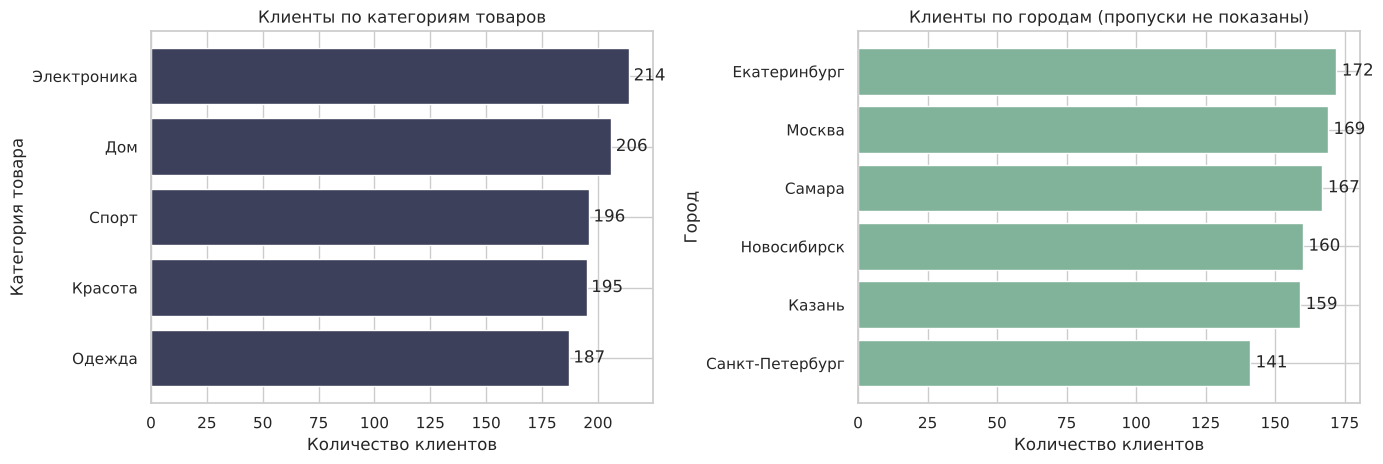

product_category
Электроника    0.214
Дом            0.206
Спорт          0.196
Красота        0.195
Одежда         0.187


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

pc = df_eda["product_category"].value_counts()
axes[0].barh(pc.index[::-1].astype(str), pc.values[::-1], color="#3d405b")
for i, v in enumerate(pc.values[::-1]):
    axes[0].text(v + 2, i, str(v), va="center")
axes[0].set_title("Клиенты по категориям товаров")
axes[0].set_xlabel("Количество клиентов"); axes[0].set_ylabel("Категория товара")

ct = df_eda["city"].value_counts()
axes[1].barh(ct.index[::-1].astype(str), ct.values[::-1], color="#81b29a")
for i, v in enumerate(ct.values[::-1]):
    axes[1].text(v + 2, i, str(v), va="center")
axes[1].set_title("Клиенты по городам (пропуски не показаны)")
axes[1].set_xlabel("Количество клиентов"); axes[1].set_ylabel("Город")
plt.tight_layout()
plt.show()
print(df_eda["product_category"].value_counts(normalize=True).round(3).to_string())

**Что видно.** Категории товаров представлены почти поровну (по 19–21%), а города — примерно по 14–17%: ни одна категория и ни один город не доминируют. После нормализации Москва стала обычным городом, а не «трёхголовой» категорией.

**Гипотезы.** Такая ровность для реальных данных нетипична (обычно один-два города/категории доминируют), что подтверждает синтетическое происхождение датасета. Результаты, полученные на этих данных, нельзя переносить на реальный магазин без проверки.

**Вопросы.** Строится ли выборка по квотам? Один клиент — одна категория: что делать с теми, кто покупает в нескольких категориях?

### 4.3. Зависимость: число заказов и сумма покупок

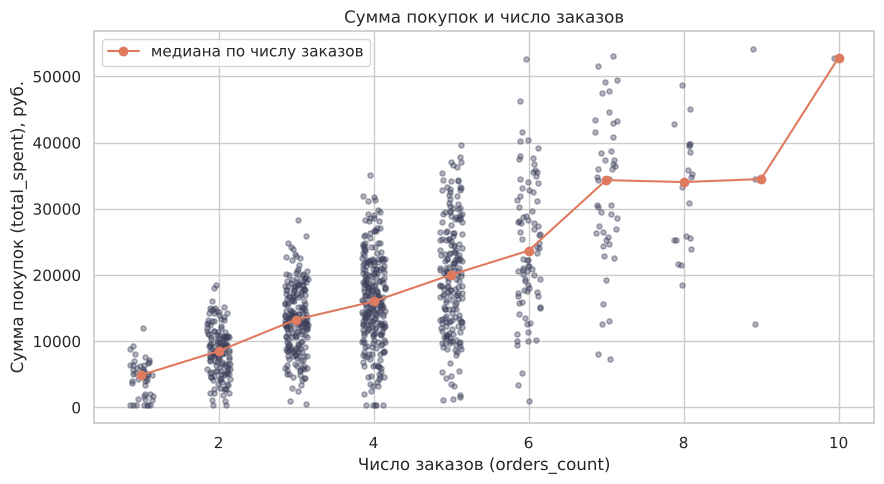

Корреляция Спирмена: 0.64


In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
rng = np.random.default_rng(42)
x = df_eda["orders_count"] + rng.uniform(-0.15, 0.15, len(df_eda))   # небольшой «джиттер»
ax.scatter(x, df_eda["total_spent"], s=14, alpha=0.4, color="#3d405b")
med_by_n = df_eda.groupby("orders_count")["total_spent"].median()
ax.plot(med_by_n.index, med_by_n.values, "o-", color="#e07a5f", label="медиана по числу заказов")
ax.set_title("Сумма покупок и число заказов")
ax.set_xlabel("Число заказов (orders_count)")
ax.set_ylabel("Сумма покупок (total_spent), руб.")
ax.legend()
plt.tight_layout()
plt.show()
rho = df_eda[["orders_count", "total_spent"]].corr(method="spearman").iloc[0, 1]
print(f"Корреляция Спирмена: {rho:.2f}")

**Что видно.** Чем больше заказов, тем выше сумма покупок: медиана растёт почти линейно (около 5 тысяч при одном заказе, 16 при четырёх, 34 при семи-девяти), но разброс при каждом числе заказов заметный. Корреляция Спирмена ≈ 0.64. При 9–10 заказах клиентов очень мало (4 человека), поэтому там медиане доверять нельзя.

**Гипотезы.** Сумма — это примерно число заказов × средний чек, а разброс создаёт чек: клиенты с одинаковым числом заказов различаются именно размером чека. Значит, для сегментации важны оба признака, а не только частота.

**Вопросы.** Если `total_spent` вычисляется из других столбцов, нужно ли предсказывать его в задаче регрессии (утечка цели)?

### 4.4. Зависимость: категория товара и сумма покупок

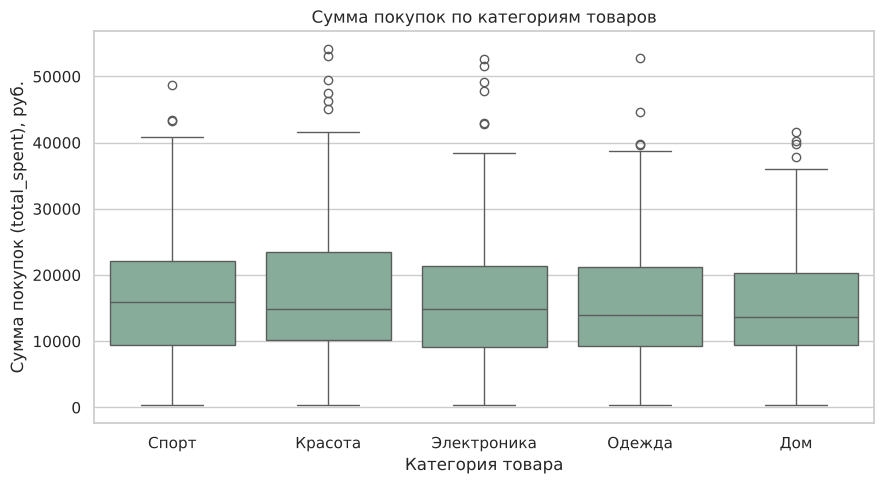

product_category
Спорт          15891.0
Красота        14927.0
Электроника    14896.0
Одежда         13954.0
Дом            13692.0


In [24]:
order = df_eda.groupby("product_category", observed=True)["total_spent"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df_eda, x="product_category", y="total_spent", order=order, color="#81b29a", ax=ax)
ax.set_title("Сумма покупок по категориям товаров")
ax.set_xlabel("Категория товара")
ax.set_ylabel("Сумма покупок (total_spent), руб.")
plt.tight_layout()
plt.show()
print(df_eda.groupby("product_category", observed=True)["total_spent"].median().round(0).sort_values(ascending=False).to_string())

**Что видно.** Медианы по категориям близки (от ≈ 13.7 тысяч у «Дома» до ≈ 15.9 у «Спорта»), «ящики» сильно перекрываются.

**Гипотезы.** Категория товара почти не объясняет сумму покупок: различия небольшие и могут быть случайными (проверить тестом Краскела–Уоллиса).

**Вопросы.** Различаются ли категории по среднему чеку, а не по сумме? Не нужно ли смотреть на сочетание «категория × город»?

### 4.5. Корреляции числовых признаков

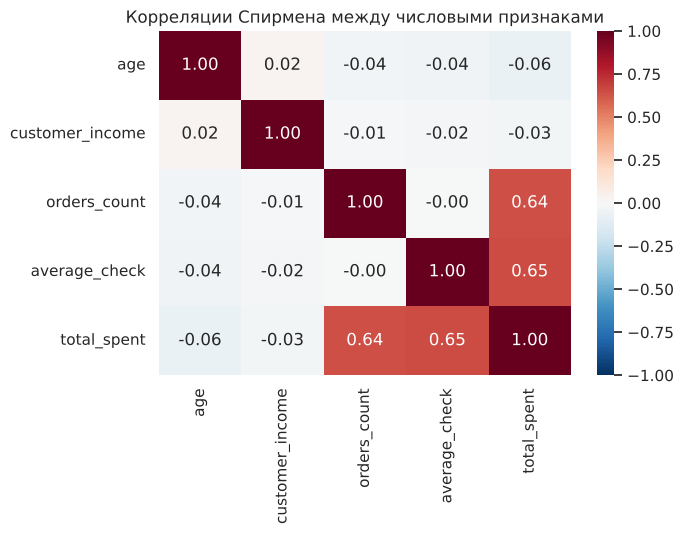

In [25]:
num_eda = ["age", "customer_income", "orders_count", "average_check", "total_spent"]
corr = df_eda[num_eda].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Корреляции Спирмена между числовыми признаками")
plt.tight_layout()
plt.show()

**Что видно.** Сумма покупок связана только с числом заказов и средним чеком (≈ 0.6 с каждым). Возраст и доход практически не коррелируют ни с чем (|ρ| < 0.1), даже друг с другом.

**Гипотезы.** Демографические признаки в этом датасете почти не несут информации о поведении клиента, поэтому на них не стоит рассчитывать при прогнозе `total_spent`; для сегментации они пригодны как описательные.

**Вопросы.** Нет ли нелинейных зависимостей, которые не ловит корреляция (например, доход — «ступенчатый» эффект)?

### 4.6. Динамика заказов по месяцам

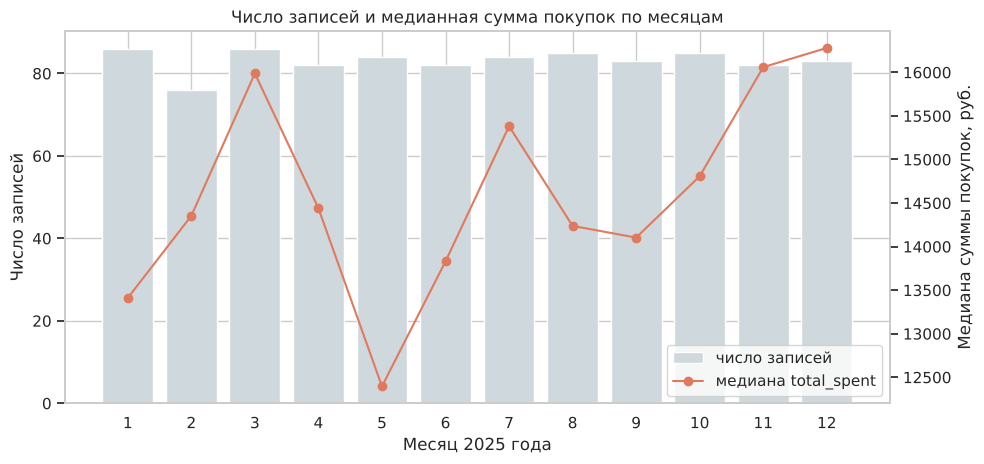

In [26]:
monthly = df_eda.groupby("month").agg(клиентов=("customer_id", "count"), медиана=("total_spent", "median"))
fig, ax1 = plt.subplots(figsize=(10, 4.8))
ax1.bar(monthly.index, monthly["клиентов"], color="#cfd8dc", label="число записей")
ax1.set_xlabel("Месяц 2025 года"); ax1.set_ylabel("Число записей")
ax1.set_xticks(range(1, 13))
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["медиана"], "o-", color="#e07a5f", label="медиана total_spent")
ax2.set_ylabel("Медиана суммы покупок, руб."); ax2.grid(False)
ax1.set_title("Число записей и медианная сумма покупок по месяцам")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower right")
plt.tight_layout()
plt.show()

**Что видно.** Записей в каждом месяце примерно поровну, то есть даты заказов распределены по году равномерно (даже слишком: шаг между соседними датами почти постоянен). Медианная сумма колеблется между месяцами без чёткой сезонности.

**Гипотезы.** `order_date` сгенерирована как равномерная сетка и вряд ли отражает реальную сезонность. Различия медиан по месяцам вероятнее всего шум.

**Вопросы.** Что означает `order_date` для клиента с несколькими заказами — дату первого, последнего заказа или регистрации? Без ответа нельзя строить признаки «давность» и «частота».

# 5. Дополнительно: шкалы признаков и природа пропусков

## 5.1. Шкалы измерения

| Признак | Шкала | Комментарий |
| :--- | :--- | :--- |
| `customer_id` | номинальная | идентификатор, арифметика не имеет смысла |
| `order_date` | интервальная | календарное время без естественного нуля |
| `age` | отношений | есть абсолютный ноль, равные интервалы |
| `gender`, `city`, `product_category`, `payment_method` | номинальная | категории без порядка |
| `orders_count` | отношений (дискретная) | счётчик |
| `average_check`, `total_spent`, `customer_income` | отношений | денежные суммы, есть ноль |

Для номинальных признаков корректны только мода и частоты, для остальных — медиана и среднее. Средний чек и суммы сильно скошены, поэтому надёжнее медиана.

## 5.2. Природа пропусков в `customer_income` (MCAR / MAR)

Это признак с наибольшей долей пропусков. Проверим, зависит ли факт пропуска от других признаков: если нет, пропуски похожи на MCAR (полностью случайные), если да — на MAR.

In [27]:
miss = df_clean["customer_income"].isna()
print(f"Пропусков дохода: {int(miss.sum())}\n")

# числовые признаки: критерий Манна–Уитни (не требует нормальности)
for c in ["age", "orders_count", "average_check", "total_spent"]:
    a = df_clean.loc[~miss, c].dropna().astype(float)
    b = df_clean.loc[miss, c].dropna().astype(float)
    p = stats.mannwhitneyu(a, b).pvalue
    print(f"{c:15s} Манн–Уитни p = {p:.3f}   медиана при наличии дохода / при пропуске: {a.median():.0f} / {b.median():.0f}")

# категориальные: хи-квадрат
print()
for c in ["gender", "city", "product_category", "payment_method"]:
    tbl = pd.crosstab(df_clean[c], miss)
    p = stats.chi2_contingency(tbl)[1]
    print(f"{c:17s} хи-квадрат p = {p:.3f}")

Пропусков дохода: 60

age             Манн–Уитни p = 0.131   медиана при наличии дохода / при пропуске: 35 / 33
orders_count    Манн–Уитни p = 0.731   медиана при наличии дохода / при пропуске: 4 / 4
average_check   Манн–Уитни p = 0.131   медиана при наличии дохода / при пропуске: 4151 / 3980
total_spent     Манн–Уитни p = 0.271   медиана при наличии дохода / при пропуске: 14899 / 13188

gender            хи-квадрат p = 0.306
city              хи-квадрат p = 0.657
product_category  хи-квадрат p = 0.814
payment_method    хи-квадрат p = 0.803


**Вывод.** Ни по одному из восьми признаков значимых различий нет (все p > 0.05), поэтому пропуски дохода согласуются с **MCAR**: они выглядят как случайно «выпавшие» значения. Но отсутствие значимости не доказывает MCAR (выборка пропусков небольшая, всего 60), а MNAR (пропуск зависит от самого дохода) данные проверить принципиально не позволяют. Практически это означает: заполнение медианой не должно сильно сместить анализ, но заменой неявных пропусков (`25000`) стоит заняться отдельно.

# 6. Итоги аудита

| № | Проблема | Масштаб | Решение |
| :-: | :--- | :--- | :--- |
| 1 | Пропуски | `customer_income` 6.1%, `age` 4.9%, `average_check` 4.1%, `city` 3.0% | импутация; `average_check` — пересчёт из `total_spent/orders_count` |
| 2 | Полные дубликаты | 3 строки (`C0051`–`C0053`) | удалены |
| 3 | Невозможный возраст | 3 значения (−5, 0, 150) | заменены на пропуск |
| 4 | «Грязные» категории | `city` (Москва в 3 написаниях), `payment_method` (`' карта '`) | нормализованы |
| 5 | Экстремальные суммы | `total_spent` = 500 000 и 750 000 | проверить у источника, исключить из обучения |
| 6 | Нереалистичный средний чек | 45 000, 60 000, 85 000 | заменить на пропуск и восстановить |
| 7 | Значения-«заглушки» на границах | `300` (13), `500` (8), `25000` (11) | выяснить смысл, при необходимости пометить |
| 8 | Нарушение `total_spent ≈ orders_count × average_check` | около 50 строк | проверить, использовать как признак аномальности |
| 9 | Искусственно ровные даты и распределения | `order_date`, категории | учесть при интерпретации; синтетика |

Подробное описание, риски и приоритеты — в `report/quality_report.md`.